# Model 2: Support Vector Machine (SVM)
Dataset:** Plant Disease Recognition (Healthy / Powdery / Rust)

**Category:** Classification

## Model suitability
The dataset is small (~1,300 training images) and the classes differ mainly in colour and texture
(rust = orange-brown spots, powdery mildew = white patches). SVMs work well on small, high-dimensional data and the
RBF kernel can model non-linear boundaries between classes.

## Implementation details
`sklearn.svm.SVC` inside a `Pipeline`. Two feature sets: (a) flattened pixels reduced by PCA (fitted inside the pipeline, so no leakage),
(b) the 512-value RGB colour histogram from the group pipeline.

## Parameter tuning method
Manual comparison of kernel, C and feature set, then `GridSearchCV` (5-fold) over C and gamma on the better feature set.

## Evaluation metric & validation method
Accuracy plus per-class precision, recall and F1 and a confusion matrix, because errors between specific
diseases matter more than overall accuracy alone. Varieties are **selected by 5-fold CV accuracy on Train**.
Validation and Test accuracy are reported for the final comparison (the test set is used once, not for choosing).

In [1]:
# ---- Configuration (paths are relative to the notebooks/ folder) ----
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
warnings.filterwarnings('ignore')

DATA_ROOT = '../data/raw'      # folder that contains Train/, Validation/ and Test/
SPLITS = {s: os.path.join(DATA_ROOT, s, s) for s in ['Train', 'Validation', 'Test']}  # dataset is nested: Train/Train/...
RESULTS = '../results'
os.makedirs(f'{RESULTS}/eda_visualizations', exist_ok=True)
os.makedirs(f'{RESULTS}/outputs', exist_ok=True)

CLASS_NAMES = sorted(d for d in os.listdir(SPLITS['Train']) if os.path.isdir(os.path.join(SPLITS['Train'], d)))
print('Classes:', CLASS_NAMES)
for s, p in SPLITS.items():
    print(s, {c: len(os.listdir(os.path.join(p, c))) for c in CLASS_NAMES})

Classes: ['Healthy', 'Powdery', 'Rust']
Train {'Healthy': 458, 'Powdery': 430, 'Rust': 434}
Validation {'Healthy': 20, 'Powdery': 20, 'Rust': 20}
Test {'Healthy': 50, 'Powdery': 50, 'Rust': 50}


In [2]:
# Helper: every notebook appends its results to one shared CSV (used later for the group comparison)
def log_result(model, variety, val_acc=None, test_acc=None, notes=''):
    path = f'{RESULTS}/outputs/model_results.csv'
    cols = ['model', 'variety', 'val_accuracy', 'test_accuracy', 'notes']
    df = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame(columns=cols)
    df = df[~((df['model'] == model) & (df['variety'] == variety))].reset_index(drop=True)
    df.loc[len(df)] = [model, variety, val_acc, test_acc, notes]
    df.to_csv(path, index=False)

In [3]:
# ---- Flat features for classical ML (same preprocessing as the group pipeline) ----
#   pixels    : 64x64x3 image flattened and scaled to 0-1  (12,288 values)
#   histogram : 8x8x8 RGB colour histogram               (512 values)
def hist_feat(img):
    h = cv2.calcHist([img], [0, 1, 2], None, [8, 8, 8], [0, 256] * 3)
    return cv2.normalize(h, h).flatten()

def build_features(split, flat_size=64):
    Xp, Xh, y = [], [], []
    for idx, c in enumerate(CLASS_NAMES):
        folder = os.path.join(SPLITS[split], c)
        for f in sorted(os.listdir(folder)):
            if not f.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue
            try:
                img = np.array(Image.open(os.path.join(folder, f)).convert('RGB').resize((128, 128)))
            except Exception:
                continue                      # skip unreadable files
            Xh.append(hist_feat(img))
            Xp.append(cv2.resize(img, (flat_size, flat_size)).flatten() / 255.0)
            y.append(idx)
    return np.array(Xp, dtype='float32'), np.array(Xh, dtype='float32'), np.array(y)

CACHE = f'{RESULTS}/outputs/plant_features.npz'      # built once, reused by every notebook
keys = ['Xp_tr', 'Xh_tr', 'y_tr', 'Xp_va', 'Xh_va', 'y_va', 'Xp_te', 'Xh_te', 'y_te']
if os.path.exists(CACHE):
    d = np.load(CACHE)
    Xp_tr, Xh_tr, y_tr, Xp_va, Xh_va, y_va, Xp_te, Xh_te, y_te = [d[k] for k in keys]
else:
    Xp_tr, Xh_tr, y_tr = build_features('Train')
    Xp_va, Xh_va, y_va = build_features('Validation')
    Xp_te, Xh_te, y_te = build_features('Test')
    np.savez_compressed(CACHE, **dict(zip(keys, [Xp_tr, Xh_tr, y_tr, Xp_va, Xh_va, y_va, Xp_te, Xh_te, y_te])))
print('Train', Xp_tr.shape, Xh_tr.shape, '| Val', Xp_va.shape, '| Test', Xp_te.shape)

Train (1322, 12288) (1322, 512) | Val (60, 12288) | Test (150, 12288)


In [4]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
import seaborn as sns

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def show_confusion(y_true, y_pred, title, fname):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(title); plt.tight_layout()
    plt.savefig(f'{RESULTS}/eda_visualizations/{fname}', dpi=200)
    plt.show()

In [9]:
from sklearn.svm import SVC
from sklearn.metrics import f1_score
N_PCA = 100
DATA = {'pixels+PCA': (Xp_tr, Xp_va, Xp_te), 'histogram': (Xh_tr, Xh_va, Xh_te)}

def make_pipe(feats, kernel, C, gamma='scale'):
    steps = [('pca', PCA(N_PCA, random_state=42))] if feats == 'pixels+PCA' else []
    steps.append(('svc', SVC(kernel=kernel, C=C, gamma=gamma)))
    return Pipeline(steps)

varieties = [
    ('V1 linear, C=1',        'pixels+PCA', 'linear', 1),
    ('V2 RBF, C=1',           'pixels+PCA', 'rbf', 1),
    ('V3 RBF, C=10',          'pixels+PCA', 'rbf', 10),
    ('V4 RBF, C=10',          'histogram',  'rbf', 10),
]
rows, fitted = [], {}
for name, feats, kernel, C in varieties:
    Xtr, Xva, Xte = DATA[feats]
    pipe = make_pipe(feats, kernel, C)
    cv_acc = cross_val_score(pipe, Xtr, y_tr, cv=cv).mean()
    pipe.fit(Xtr, y_tr)
    pred_te = pipe.predict(Xte)
    rows.append([name, feats, cv_acc, accuracy_score(y_va, pipe.predict(Xva)),
                 accuracy_score(y_te, pred_te), f1_score(y_te, pred_te, average='macro')])
    fitted[name] = (pipe, feats)
comparison = pd.DataFrame(rows, columns=['Variety', 'Features', 'CV acc (Train)', 'Val acc',
                                         'Test acc', 'Test macro-F1']).round(3)
comparison

,Variety,Features,CV acc (Train),Val acc,Test acc,Test macro-F1
0,"V1 linear, C=1",pixels+PCA,0.778,0.683,0.627,0.628
1,"V2 RBF, C=1",pixels+PCA,0.840,0.750,0.720,0.713
2,"V3 RBF, C=10",pixels+PCA,0.817,0.750,0.673,0.671
3,"V4 RBF, C=10",histogram,0.837,0.800,0.833,0.832


In [13]:
# V5: GridSearchCV on the better feature set (chosen by CV accuracy of V3 vs V4)
comparison = comparison[~comparison['Variety'].str.startswith('V5')].reset_index(drop=True)
best_feats = comparison.iloc[2:4].sort_values('CV acc (Train)', ascending=False).iloc[0]['Features']
print('Feature set used for grid search:', best_feats)
grid = GridSearchCV(make_pipe(best_feats, 'rbf', 1),
                    {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': ['scale', 0.01, 0.1, 1]},
                    cv=cv, n_jobs=-1)
Xtr, Xva, Xte = DATA[best_feats]
grid.fit(Xtr, y_tr)
print('Best params:', grid.best_params_, '| best CV acc:', round(grid.best_score_, 3))
v5 = f"V5 grid search ({best_feats})"
pred_te = grid.predict(Xte)
comparison.loc[len(comparison)] = [v5, best_feats, round(grid.best_score_, 3),
                                   round(accuracy_score(y_va, grid.predict(Xva)), 3),
                                   round(accuracy_score(y_te, pred_te), 3),
                                   round(f1_score(y_te, pred_te, average='macro'), 3)]
fitted[v5] = (grid.best_estimator_, best_feats)
comparison

Feature set used for grid search: histogram
Best params: {'svc__C': 100, 'svc__gamma': 1} | best CV acc: 0.843


,Variety,Features,CV acc (Train),Val acc,Test acc,Test macro-F1
0,"V1 linear, C=1",pixels+PCA,0.778,0.683,0.627,0.628
1,"V2 RBF, C=1",pixels+PCA,0.840,0.750,0.720,0.713
2,"V3 RBF, C=10",pixels+PCA,0.817,0.750,0.673,0.671
3,"V4 RBF, C=10",histogram,0.837,0.800,0.833,0.832
4,V5 grid search (histogram),histogram,0.843,0.783,0.813,0.813


## Comparison across varieties
Use the table above. Compare linear vs RBF, effect of C, pixels+PCA vs colour histogram, and whether grid search helped.

Selected: V5 grid search (histogram)
              precision    recall  f1-score   support

     Healthy       0.80      0.78      0.79        50
     Powdery       0.87      0.90      0.88        50
        Rust       0.78      0.76      0.77        50

    accuracy                           0.81       150
   macro avg       0.81      0.81      0.81       150
weighted avg       0.81      0.81      0.81       150



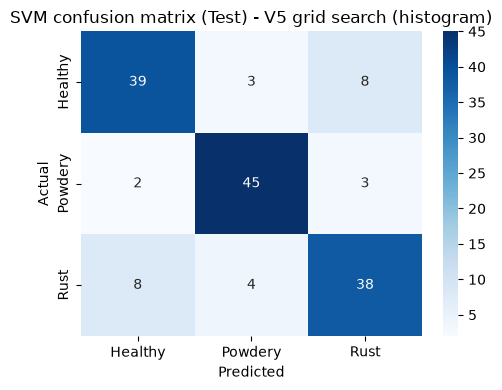

In [12]:
# Final model = highest CV accuracy; evaluate once on Test
best_name = comparison.sort_values('CV acc (Train)', ascending=False).iloc[0]['Variety']
best_pipe, best_f = fitted[best_name]
Xte_best = DATA[best_f][2]
y_pred = best_pipe.predict(Xte_best)
print('Selected:', best_name)
print(classification_report(y_te, y_pred, target_names=CLASS_NAMES))
show_confusion(y_te, y_pred, f'SVM confusion matrix (Test) - {best_name}', 'svm_confusion_matrix.png')
for _, r in comparison.iterrows():
    log_result('SVM', r['Variety'], r['Val acc'], r['Test acc'], f"cv={r['CV acc (Train)']}")

## Conclusion 

**Variety Selected and Why:**
The **V5 grid search (histogram)** model was selected as the final model because it achieved the highest cross-validation accuracy on the training set at 0.843. The grid search process optimized the Support Vector Classifier by selecting an RBF kernel with C=100 and gamma=1, yielding a strong balance between training fit and generalization with a final test accuracy of 0.813 and a test macro-F1 score of 0.813.

**Feature Set Comparison:**
The 512-value RGB color histogram features significantly outperformed the PCA-reduced flattened pixel features. When comparing the baseline RBF model (C=10), the model utilizing the color histogram (V4) achieved a test accuracy of 0.833, whereas the same model using PCA pixels (V3) only achieved 0.673. This performance gap indicates that for this specific dataset, color distribution is a much stronger predictor of disease than spatial pixel configurations, which aligns with the visual nature of the diseases (rust producing orange-brown spots and powdery mildew producing white patches).

**Class Confusion Analysis:**
Based on the classification report, the model was highly effective at identifying the "Powdery" class, achieving the highest precision (0.87) and recall (0.90). The stark white patches of powdery mildew likely create a very distinct color histogram signature. Conversely, the model struggled more with the "Rust" class, which had the lowest recall (0.76), and the "Healthy" class, which had the lowest precision (0.80). This suggests that the SVM occasionally confused healthy leaves with rust-infected leaves, likely because early-stage rust spots are small and their color profiles may heavily overlap with the dominant green hues of a standard healthy leaf.